# Import packages

In [84]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt

# Data processing

In [85]:
path = "/media/sergio/Meninges/troutpy/xenium_rep2_breast/data.zarr"
sdata = sd.read_zarr(path)

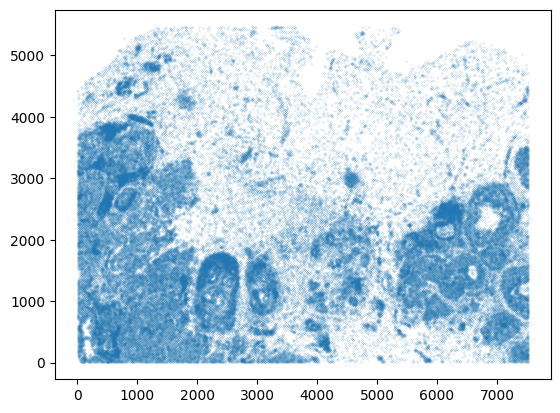

In [86]:
spat = [g[0] for g in sdata["table"].obsm["spatial"]]
spat2 = [g[1] for g in sdata["table"].obsm["spatial"]]
plt.scatter(spat, spat2, s=0.01)

In [87]:
cropped_sdata = sdata.query.bounding_box(
    axes=["x", "y"],
    min_coordinate=[5000, 5000],
    max_coordinate=[15000, 20000],
    target_coordinate_system="global",
)
sdata = cropped_sdata

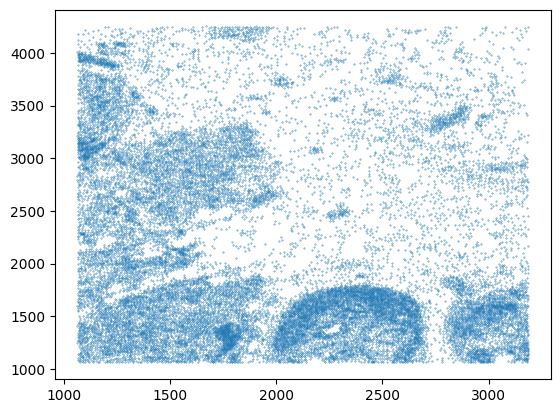

In [88]:
spat = [g[0] for g in sdata["table"].obsm["spatial"]]
spat2 = [g[1] for g in sdata["table"].obsm["spatial"]]
plt.scatter(spat, spat2, s=0.1)

In [89]:
transcripts = sdata["transcripts"].compute()
transcripts.reset_index(drop=True, inplace=True)
sdata["transcripts"] = sd.models.PointsModel.parse(transcripts)

In [93]:
path = "/media/sergio/Meninges/troutpy/xenium_rep2_breast/data_cropped.zarr"
sdata.write(path, overwrite=True)

ValueError: Attempt to save array to zarr with irregular chunking, please call `arr.rechunk(...)` first.

In [118]:
troutpy.pp.define_extracellular(sdata, layer="transcripts", method="cells", unassigned_tag=-1)

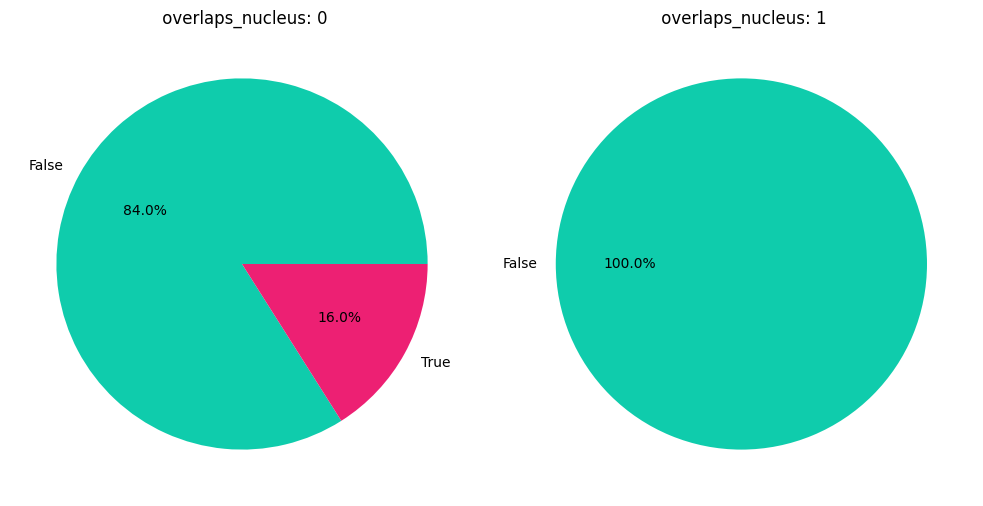

In [249]:
troutpy.pl.pie(sdata, groupby="extracellular", group_key="overlaps_nucleus")

### Process cell expressions

(21877, 313)


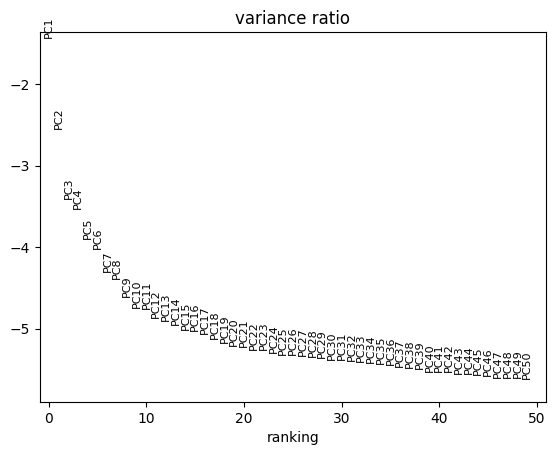

(21818, 313)


In [96]:
adata = sdata["table"]
print(adata.shape)
adata.raw = adata.copy()
sc.pp.filter_cells(adata, min_genes=10)
sc.pp.filter_genes(adata, min_cells=3)
adata.layers["raw"] = adata.X.copy()
sc.pp.normalize_total(adata)
# Logarithmize the data
sc.pp.log1p(adata)
sc.tl.pca(adata)
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)
sc.pp.neighbors(adata)
sc.tl.umap(adata)
print(adata.shape)
sc.tl.leiden(adata, key_added="leiden")

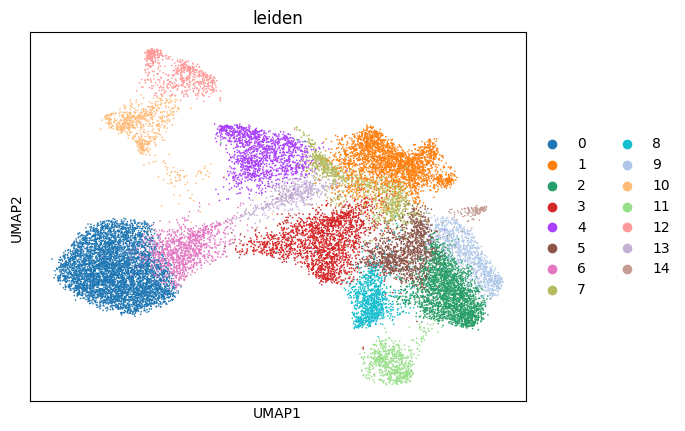

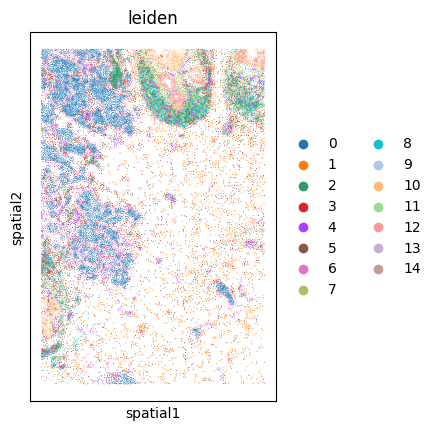

In [97]:
sc.pl.umap(adata, color="leiden")
sc.pl.spatial(adata, color="leiden", spot_size=10)

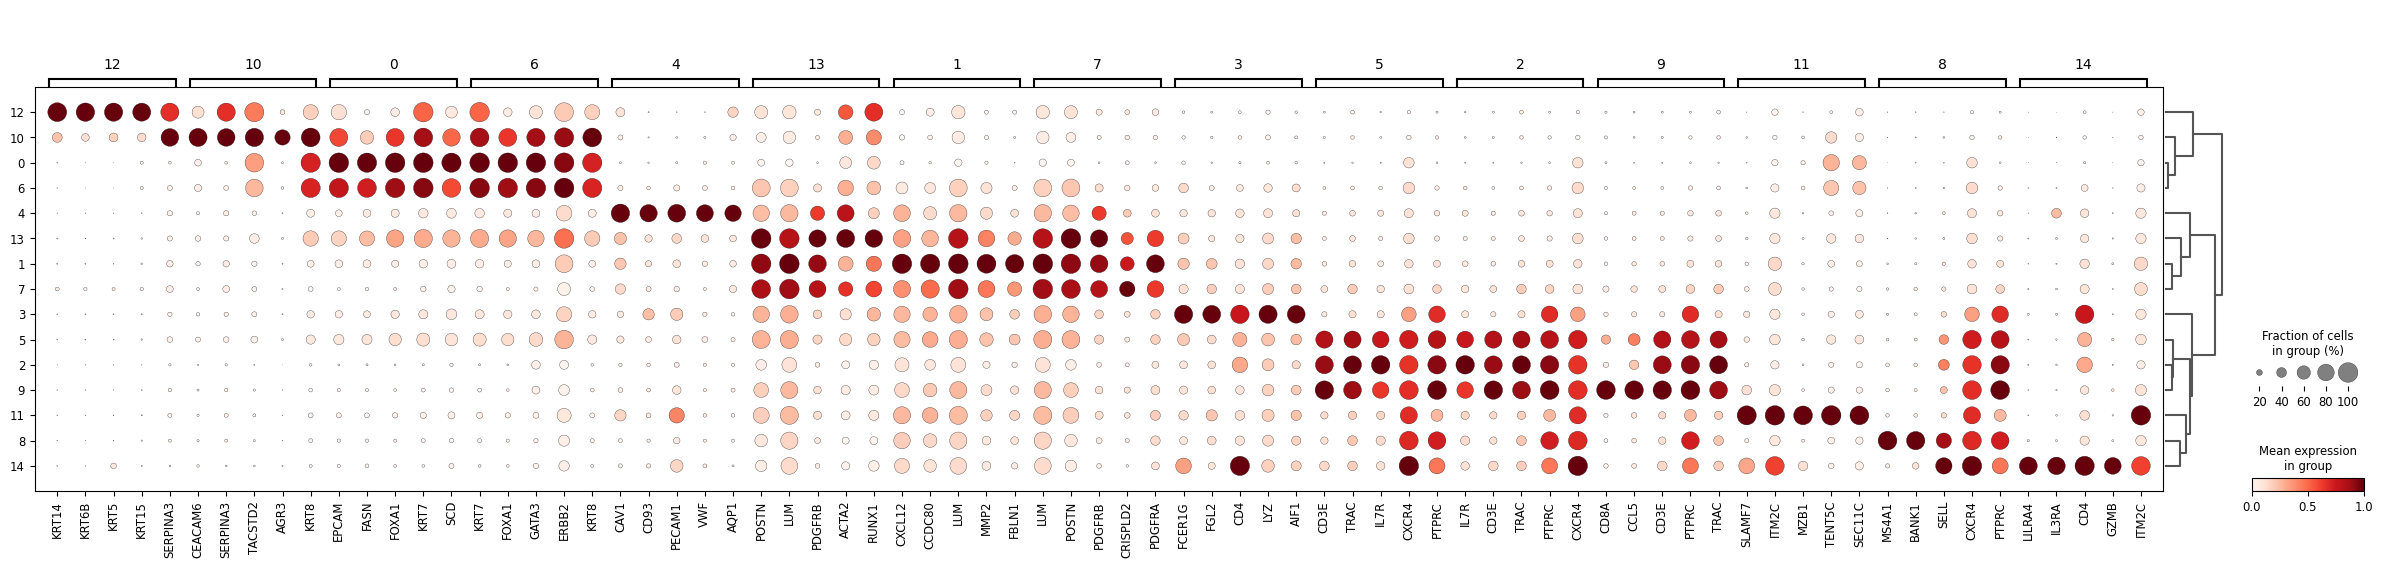

In [98]:
sc.tl.rank_genes_groups(adata, groupby="leiden", method="wilcoxon")
sc.pl.rank_genes_groups_dotplot(adata, groupby="leiden", standard_scale="var", n_genes=5)

## Quantify exRNa

In [123]:
import numpy as np

gen = np.unique(sdata["transcripts"]["feature_name"].compute())
control_codewords = [g for g in gen if "Con" in g]

troutpy.tl.quantify_overexpression(
    sdata,
    layer="transcripts",
    codeword_key="feature_name",
    control_codewords=control_codewords,
    gene_key="feature_name",
    percentile_threshold=99.99,
)

True


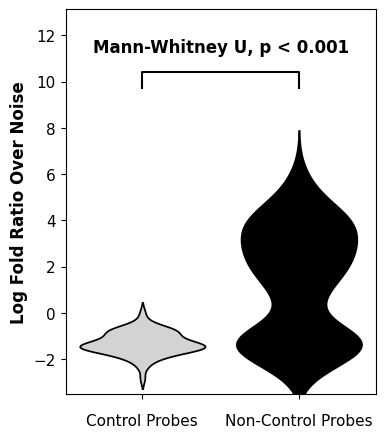

In [124]:
troutpy.pl.logfoldratio_over_noise(sdata, test_method="auto")

In [126]:
troutpy.tl.extracellular_enrichment(sdata)

In [128]:
sdata["xrna_metadata"]

AnnData object with n_obs × n_vars = 0 × 541
    var: 'count', 'logfoldratio_over_noise', 'control_probe', 'p_value_Poisson', 'intracellular_proportion', 'extracellular_proportion', 'logfoldratio_extracellular'

# Test diffussion

In [145]:
troutpy.pp.filter_xrna?

Signature:
troutpy.pp.filter_xrna(
    sdata,
    min_counts=None,
    min_extracellular_proportion=None,
    control_probe=None,
    min_logfoldratio_over_noise=1,
    min_morani=None,
    gene_key='feature_name',
    filter_cellular=False,
    copy=False,
)
Docstring:
Filters xRNA based on specified criteria and updates the sdata object.

Parameters
----------
    sdata: dict-like
        Spatial data object containing xRNA metadata and transcript information.
    min_counts: int, optional
        Minimum count threshold for xRNA selection.
    min_extracellular_proportion: float, optional
        Minimum extracellular proportion threshold for xRNA selection.
    control_probe: bool, optional
        If False, filters out control probes.
    min_logfoldratio_over_noise: float, default=1
        Minimum log fold-change over noise threshold for xRNA selection.
    min_morani: float, optional
        Minimum Moran's I threshold for spatial autocorrelation.
    gene_key: str, default='fe

In [146]:
troutpy.pp.filter_xrna(sdata, min_logfoldratio_over_noise=3, filter_cellular=True)
troutpy.pp.filter_xrna(sdata, min_counts=100, filter_cellular=True)
troutpy.pp.filter_xrna(sdata, min_extracellular_proportion=0.05, filter_cellular=True)

In [143]:
sdata["xrna_metadata"].var.sort_values(by="extracellular_proportion", ascending=False)

,count,logfoldratio_over_noise,control_probe,p_value_Poisson,intracellular_proportion,extracellular_proportion,logfoldratio_extracellular
ADH1B,21469,3.996832,False,0.0,0.683916,0.316084,-1.734831
SFRP4,62632,5.067499,False,0.0,0.699754,0.300246,-1.660533
LPL,8846,3.110188,False,0.0,0.736378,0.263622,-1.479432
SFRP1,15224,3.653095,False,0.0,0.787835,0.212165,-1.194735
CCDC80,107346,5.606280,False,0.0,0.790304,0.209696,-1.179899
...,...,...,...,...,...,...,...
CCL5,12191,3.430920,False,0.0,0.948569,0.051431,0.408046
TRAPPC3,21853,4.014561,False,0.0,0.948611,0.051389,0.408918
SRPK1,16756,3.748979,False,0.0,0.948794,0.051206,0.412685
LARS,28192,4.269261,False,0.0,0.948886,0.051114,0.414575


In [147]:
from tqdm import tqdm

troutpy.tl.compute_source_score(
    sdata, layer="transcripts", gene_key="feature_name", lambda_decay=0.1, copy=False, celltype_key="leiden"
)

Processing genes: 100%|██████████| 83/83 [36:38<00:00, 26.49s/it]  


In [81]:
sdata

SpatialData object
├── Images
│     ├── 'morphology_focus': DataTree[cyx] (1, 15000, 10000), (1, 7500, 5000), (1, 3749, 2500), (1, 1875, 1250), (1, 938, 625)
│     └── 'morphology_mip': DataTree[cyx] (1, 15000, 10000), (1, 7500, 5000), (1, 3749, 2500), (1, 1875, 1250), (1, 938, 625)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (15000, 10000), (7500, 5000), (3749, 2500), (1875, 1250), (938, 625)
│     └── 'nucleus_labels': DataTree[yx] (15000, 10000), (7500, 5000), (3749, 2500), (1875, 1250), (938, 625)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 9) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (22205, 1) (2D shapes)
│     ├── 'cell_circles': GeoDataFrame shape: (21877, 2) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (22037, 1) (2D shapes)
└── Tables
      ├── 'source_score': AnnData (0, 15)
      ├── 'table': AnnData (21818, 313)
      └── 'xrna_metadata': AnnData (0, 152)
with coordinate systems:
    ▸ 'global'

In [148]:
troutpy.tl.assess_diffussion(sdata, gene_key="feature_name", distance_key="distance")

In [149]:
troutpy.tl.extracellular_enrichment(sdata)

In [150]:
troutpy.tl.spatial_variability(sdata, gene_key="feature_name", n_neighbors=10, square_size=20)

Extracting gene counts: 100%|██████████| 83/83 [00:00<00:00, 5023.34it/s]


In [151]:
troutpy.pp.aggregate_extracellular_transcripts(sdata, square_size=8)
troutpy.tl.in_out_correlation(sdata, n_neighbors=20)

In [58]:
outpath = "/media/sergio/Meninges/troutpy/xenium_mouse_colon_roi_processed.zarr"
sdata.write(outpath, overwrite=True)

INFO     The SpatialData object is not self-contained (i.e. it contains some elements that are Dask-backed from    
         locations outside /media/sergio/Meninges/troutpy/xenium_mouse_colon_roi_processed.zarr). Please see the   
         documentation of `is_self_contained()` to understand the implications of working with SpatialData objects 
         that are not self-contained.                                                                              
INFO     The Zarr backing store has been changed from None the new file path:                                      
         /media/sergio/Meninges/troutpy/xenium_mouse_colon_roi_processed.zarr                                      


## Exploration of results

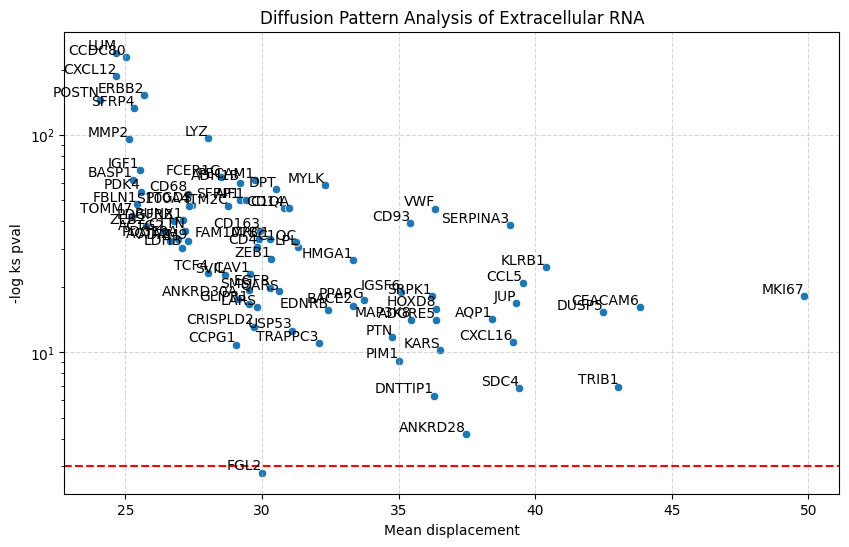

In [152]:
troutpy.pl.diffusion_results(sdata, y_col="-log_ks_pval", y_logscale=True)

Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


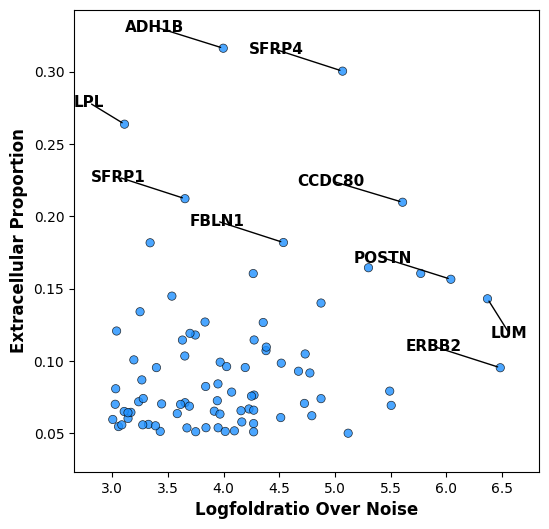

In [153]:
troutpy.pl.metric_scatter(
    sdata, x_metric="logfoldratio_over_noise", y_metric="extracellular_proportion", label_top_n_x=3, label_top_n_y=6
)

In [154]:
troutpy.tl.compare_intra_extra_distribution(sdata, copy=False, n_bins=20)

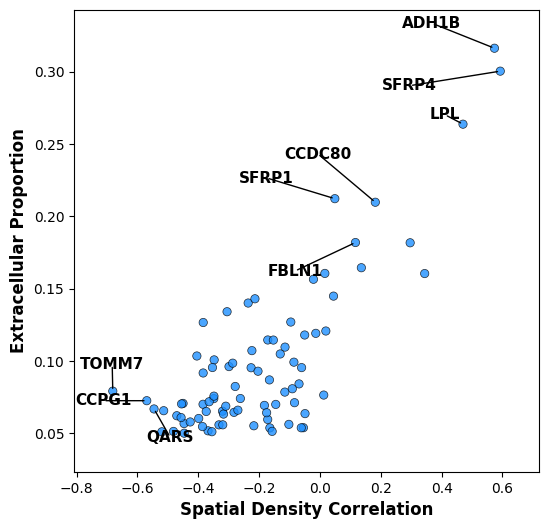

In [155]:
troutpy.pl.metric_scatter(
    sdata,
    x_metric="spatial_density_correlation",
    y_metric="extracellular_proportion",
    label_top_n_x=0,
    label_top_n_y=6,
    label_bottom_n_x=3,
)

In [156]:
bottom_genes = (
    sdata["xrna_metadata"].var.sort_values(by="spatial_density_correlation")["spatial_density_correlation"].keys()[0:6]
)
top_genes = (
    sdata["xrna_metadata"]
    .var.sort_values(by="spatial_density_correlation", ascending=False)["spatial_density_correlation"]
    .keys()[0:6]
)

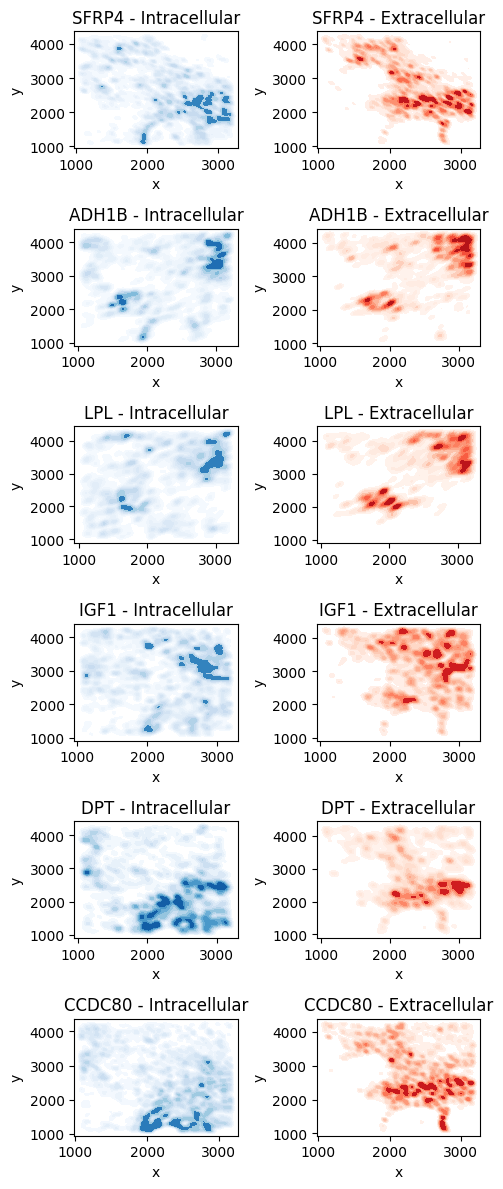

In [157]:
troutpy.pl.intra_extra_density(
    sdata,
    top_genes,
    layer="transcripts",
    gene_key="feature_name",
    coord_keys=["x", "y"],
    intra_kde_kwargs={"fill": True, "cmap": "Blues", "thresh": 0.05, "bw_adjust": 0.3},
    extra_kde_kwargs={"fill": True, "cmap": "Reds", "thresh": 0.05, "bw_adjust": 0.3},
    figsize=(5, 12),
)

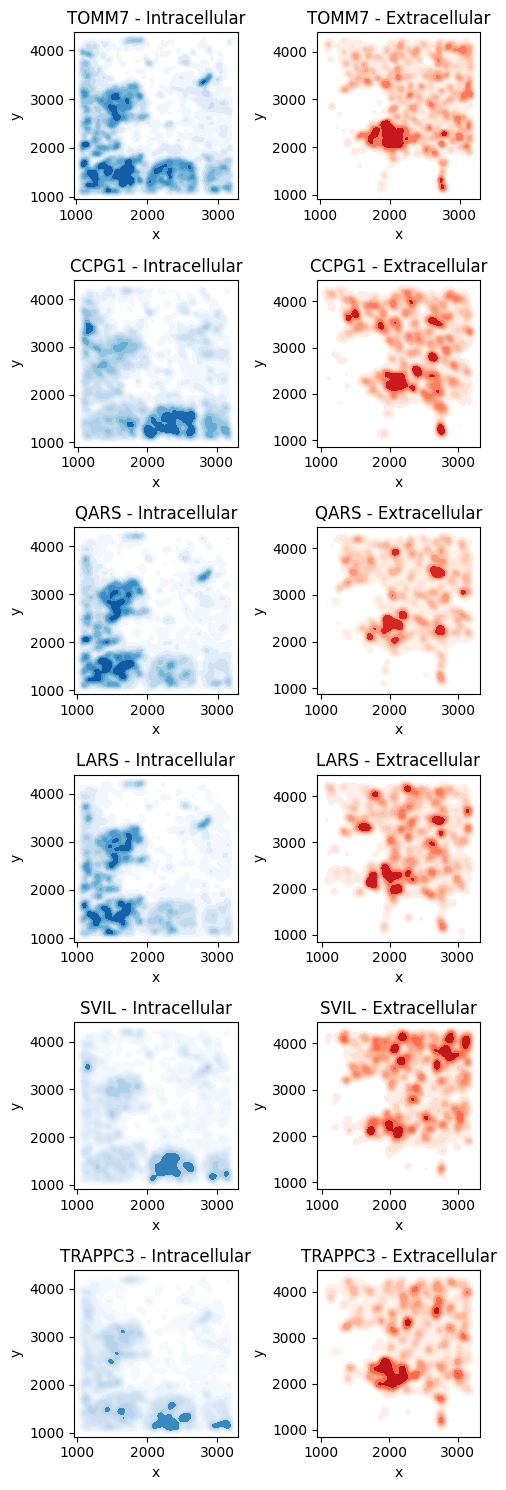

In [159]:
troutpy.pl.intra_extra_density(
    sdata,
    bottom_genes,
    layer="transcripts",
    gene_key="feature_name",
    coord_keys=["x", "y"],
    intra_kde_kwargs={"fill": True, "cmap": "Blues", "thresh": 0.05, "bw_adjust": 0.3},
    extra_kde_kwargs={"fill": True, "cmap": "Reds", "thresh": 0.05, "bw_adjust": 0.3},
    figsize=(5, 15),
)

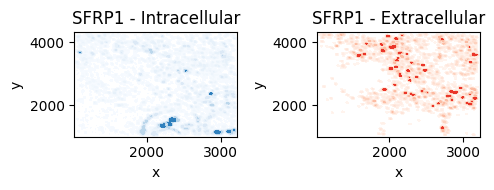

In [163]:
troutpy.pl.intra_extra_density(
    sdata,
    ["SFRP1"],
    layer="transcripts",
    gene_key="feature_name",
    coord_keys=["x", "y"],
    intra_kde_kwargs={"fill": True, "cmap": "Blues", "thresh": 0.05, "bw_adjust": 0.1},
    extra_kde_kwargs={"fill": True, "cmap": "Reds", "thresh": 0.05, "bw_adjust": 0.1},
    figsize=(5, 2),
)

In [77]:
troutpy.pp.filter_xrna(sdata, min_logfoldratio_over_noise=3)

In [164]:
troutpy.tl.compare_intra_extra_distribution(sdata, copy=False)

In [255]:
troutpy.tl.in_out_correlation(sdata, n_neighbors=40)

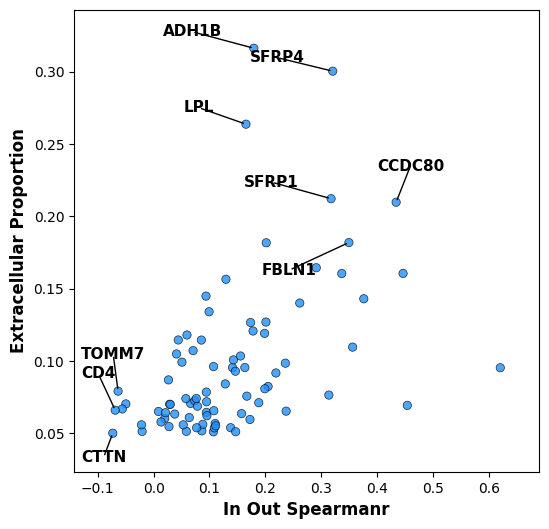

In [256]:
troutpy.pl.metric_scatter(
    sdata,
    x_metric="in_out_spearmanR",
    y_metric="extracellular_proportion",
    label_top_n_x=0,
    label_top_n_y=6,
    label_bottom_n_x=3,
)

In [253]:
sdata["xrna_metadata"].var["in_out_spearmanR"]

BASP1     0.047903
TOMM7    -0.042740
RUNX1     0.005754
CAV1      0.084308
KARS     -0.026434
            ...   
ITM2C     0.148193
PIM1      0.044691
CD4      -0.065514
PDGFRB    0.217608
S100A4    0.133226
Name: in_out_spearmanR, Length: 83, dtype: float64

In [ ]:
sdata["xrna_metadata"].var.sort_values(by="in")

<bound method DataFrame.sort_values of         count  logfoldratio_over_noise  control_probe  p_value_Poisson  \
BASP1   44784                 4.732073          False              0.0   
TOMM7   95637                 5.490782          False              0.0   
RUNX1   44490                 4.725487          False              0.0   
CAV1    20880                 3.969014          False              0.0   
KARS    12343                 3.443311          False              0.0   
...       ...                      ...            ...              ...   
ITM2C   27664                 4.250354          False              0.0   
PIM1     9127                 3.141459          False              0.0   
CD4     28211                 4.269934          False              0.0   
PDGFRB  36140                 4.517623          False              0.0   
S100A4  26149                 4.194033          False              0.0   

         ks_stat       ks_pval      ad_stat     lr_stat  mean_displaceme

In [165]:
gen = sdata["xrna_metadata"].var.sort_values(by="intracellular_proportion", ascending=True).index[0:4]
sdata["xrna_metadata"].var.sort_values(by="intracellular_proportion", ascending=True)

,count,logfoldratio_over_noise,control_probe,p_value_Poisson,ks_stat,ks_pval,ad_stat,lr_stat,mean_displacement,-log_ks_pval,...,logfoldratio_extracellular,moran_I,moran_pval_norm,moran_var_norm,moran_pval_norm_fdr_bh,in_out_spearmanR,in_out_pvalue,centroid_shift_distance,spatial_density_correlation,spatial_js_divergence
ADH1B,21469,3.996832,False,0.0,0.066987,6.407497e-27,1240.856642,543.469440,29.205744,60.312329,...,-1.291619,0.294104,0.0,0.000011,0.0,0.340930,0.000000e+00,373.130554,0.422824,0.218563
SFRP4,62632,5.067499,False,0.0,0.059449,3.248885e-58,4042.191882,2263.113270,25.321974,132.371623,...,-1.217320,0.375805,0.0,0.000011,0.0,0.481631,0.000000e+00,235.312180,0.455577,0.168361
LPL,8846,3.110188,False,0.0,0.081605,5.882497e-14,393.963461,208.706247,31.320897,30.464210,...,-1.036220,0.215148,0.0,0.000011,0.0,0.258539,0.000000e+00,366.505798,0.313844,0.287599
SFRP1,15224,3.653095,False,0.0,0.088634,1.576427e-22,585.332743,294.957500,29.188359,50.201711,...,-0.751523,0.134343,0.0,0.000011,0.0,0.235735,3.216882e-273,669.884460,0.066065,0.282738
CCDC80,107346,5.606280,False,0.0,0.071133,1.738639e-99,4809.396198,2963.858865,25.031994,227.402822,...,-0.736687,0.329084,0.0,0.000011,0.0,0.427964,0.000000e+00,443.926636,0.081670,0.222585
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
CCL5,12191,3.430920,False,0.0,0.130443,9.211340e-10,62.500173,98.373796,39.535640,20.805416,...,0.851258,0.059269,0.0,0.000011,0.0,0.051397,3.046519e-14,777.285278,-0.121567,0.513396
TRAPPC3,21853,4.014561,False,0.0,0.072015,1.646684e-05,187.936270,34.916254,32.072898,11.014162,...,0.852131,0.055560,0.0,0.000011,0.0,-0.005413,4.239945e-01,862.465271,-0.395795,0.495367
SRPK1,16756,3.748979,False,0.0,0.104401,1.349488e-08,109.223334,114.517357,36.221193,18.120956,...,0.855897,0.044118,0.0,0.000011,0.0,0.009447,1.629232e-01,806.044983,-0.277452,0.523997
LARS,28192,4.269261,False,0.0,0.076341,9.464311e-08,250.361216,91.136378,29.804391,16.173153,...,0.857787,0.062312,0.0,0.000011,0.0,-0.002219,7.430552e-01,832.577698,-0.407880,0.475510


In [61]:
gen = sdata["xrna_metadata"].var.sort_values(by="spatial_density_correlation", ascending=True).index[0:4]
sdata["xrna_metadata"].var.sort_values(by="spatial_density_correlation", ascending=True)

,count,logfoldratio_over_noise,p_value_Poisson,intracellular_proportion,extracellular_proportion,logfoldratio_extracellular,moran_I,moran_pval_norm,moran_var_norm,moran_pval_norm_fdr_bh,in_out_spearmanR,in_out_pvalue,centroid_shift_distance,spatial_density_correlation,spatial_js_divergence
Mgll,435836,4.000788,0.0,0.758866,0.241134,-0.060361,0.489629,0.0,0.000002,0.0,0.340680,0.0,63.303387,0.636961,0.051766
Bgn,560456,4.252273,0.0,0.816630,0.183370,0.286846,0.344240,0.0,0.000002,0.0,0.300215,0.0,73.513901,0.767284,0.032882
Dpt,390914,3.892010,0.0,0.735840,0.264160,-0.182376,0.390313,0.0,0.000002,0.0,0.308351,0.0,163.018616,0.782256,0.039425
Chl1,215006,3.294188,0.0,0.652428,0.347572,-0.577102,0.388354,0.0,0.000002,0.0,0.201248,0.0,106.977654,0.782540,0.035466
Sfrp1,170556,3.062586,0.0,0.805794,0.194206,0.216077,0.255329,0.0,0.000002,0.0,0.253969,0.0,113.822319,0.791838,0.036108
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Oit1,1867761,5.456018,0.0,0.860657,0.139343,0.613923,0.492231,0.0,0.000002,0.0,0.667311,0.0,143.438889,0.969365,0.012514
Tfcp2l1,1468150,5.215280,0.0,0.830938,0.169062,0.385460,0.498740,0.0,0.000002,0.0,0.631032,0.0,71.777977,0.969914,0.010797
Cldn2,611131,4.338833,0.0,0.881705,0.118295,0.801840,0.429227,0.0,0.000002,0.0,0.580331,0.0,75.898804,0.972266,0.016874
Aqp4,177059,3.100005,0.0,0.809832,0.190168,0.242085,0.362197,0.0,0.000002,0.0,0.434927,0.0,17.113632,0.972980,0.019523


## Signature analysis

In [ ]:
xenium_path_cropped = "/media/sergio/Meninges/troutpy/xenium_mouse_colon_roi_processed.zarr"
sdata = sd.read_zarr(xenium_path_cropped)

In [186]:
troutpy.pp.aggregate_extracellular_transcripts(sdata, square_size=60)

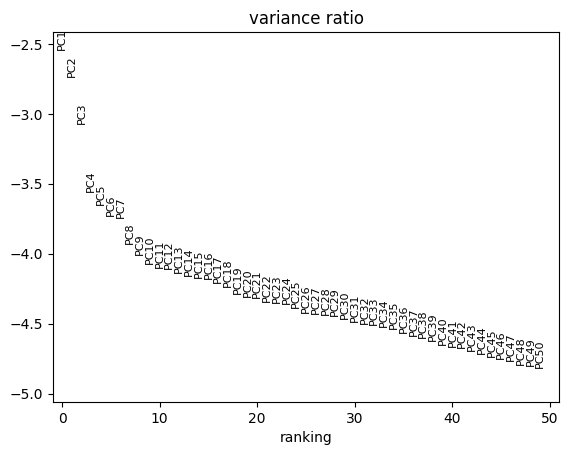

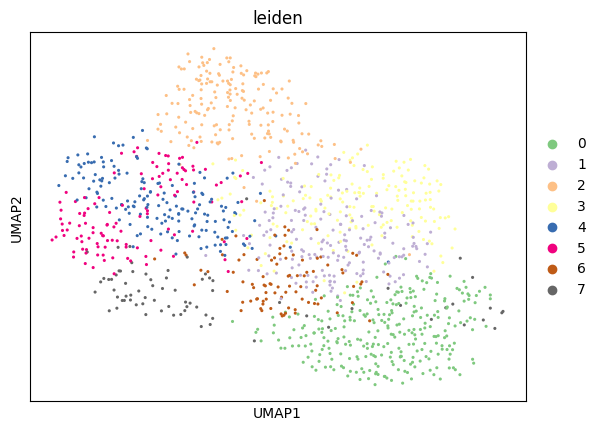

In [187]:
adata = sdata.tables["segmentation_free_table"]
adata.raw = adata
sc.pp.filter_cells(adata, min_genes=3)
sc.pp.filter_cells(adata, min_counts=10)
sc.pp.filter_genes(adata, min_cells=20)
adata.layers["raw"] = adata.X.copy()
sc.pp.normalize_total(adata)
# Logarithmize the data
sc.pp.log1p(adata)
# pca
sc.tl.pca(adata)
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)
# neighbors
sc.pp.neighbors(adata)
sc.tl.umap(adata)
sc.tl.leiden(adata, key_added="leiden", resolution=1.2)
sc.pl.umap(adata, color="leiden", palette="Accent", s=20)

[<Axes: title={'center': 'leiden'}, xlabel='spatial1', ylabel='spatial2'>]

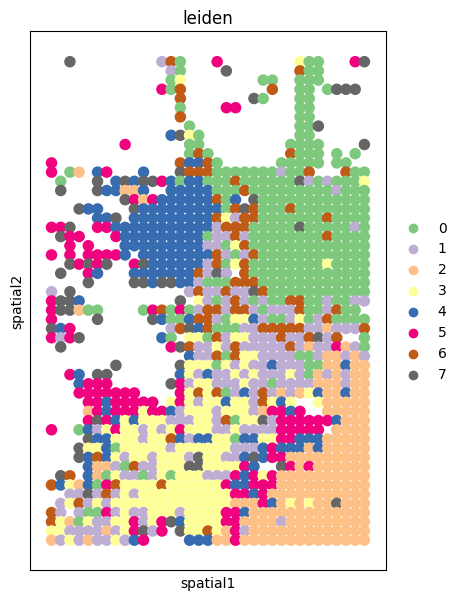

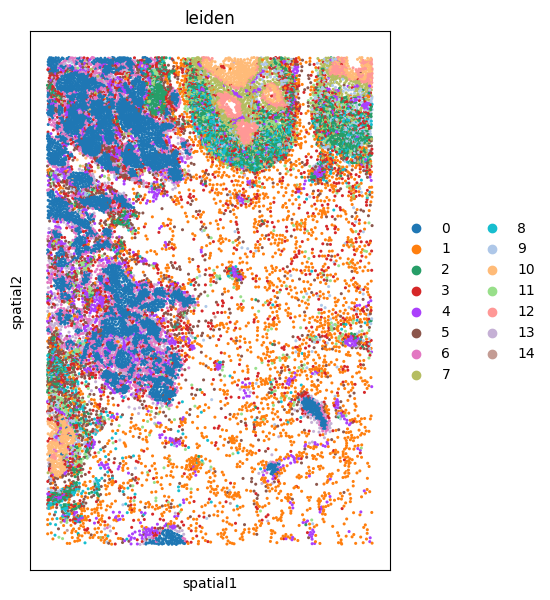

In [195]:
fig, ax = plt.subplots(figsize=(7, 7))
sc.pl.spatial(adata, color="leiden", spot_size=75, show=False, ax=ax, marker="s")
fig, ax = plt.subplots(figsize=(7, 7))
sc.pl.spatial(
    sdata["table"],
    color="leiden",
    spot_size=20,
    show=False,
    ax=ax,
    marker="*",
    outline_width=(0.8, 0.05),
    outline_color="black",
)

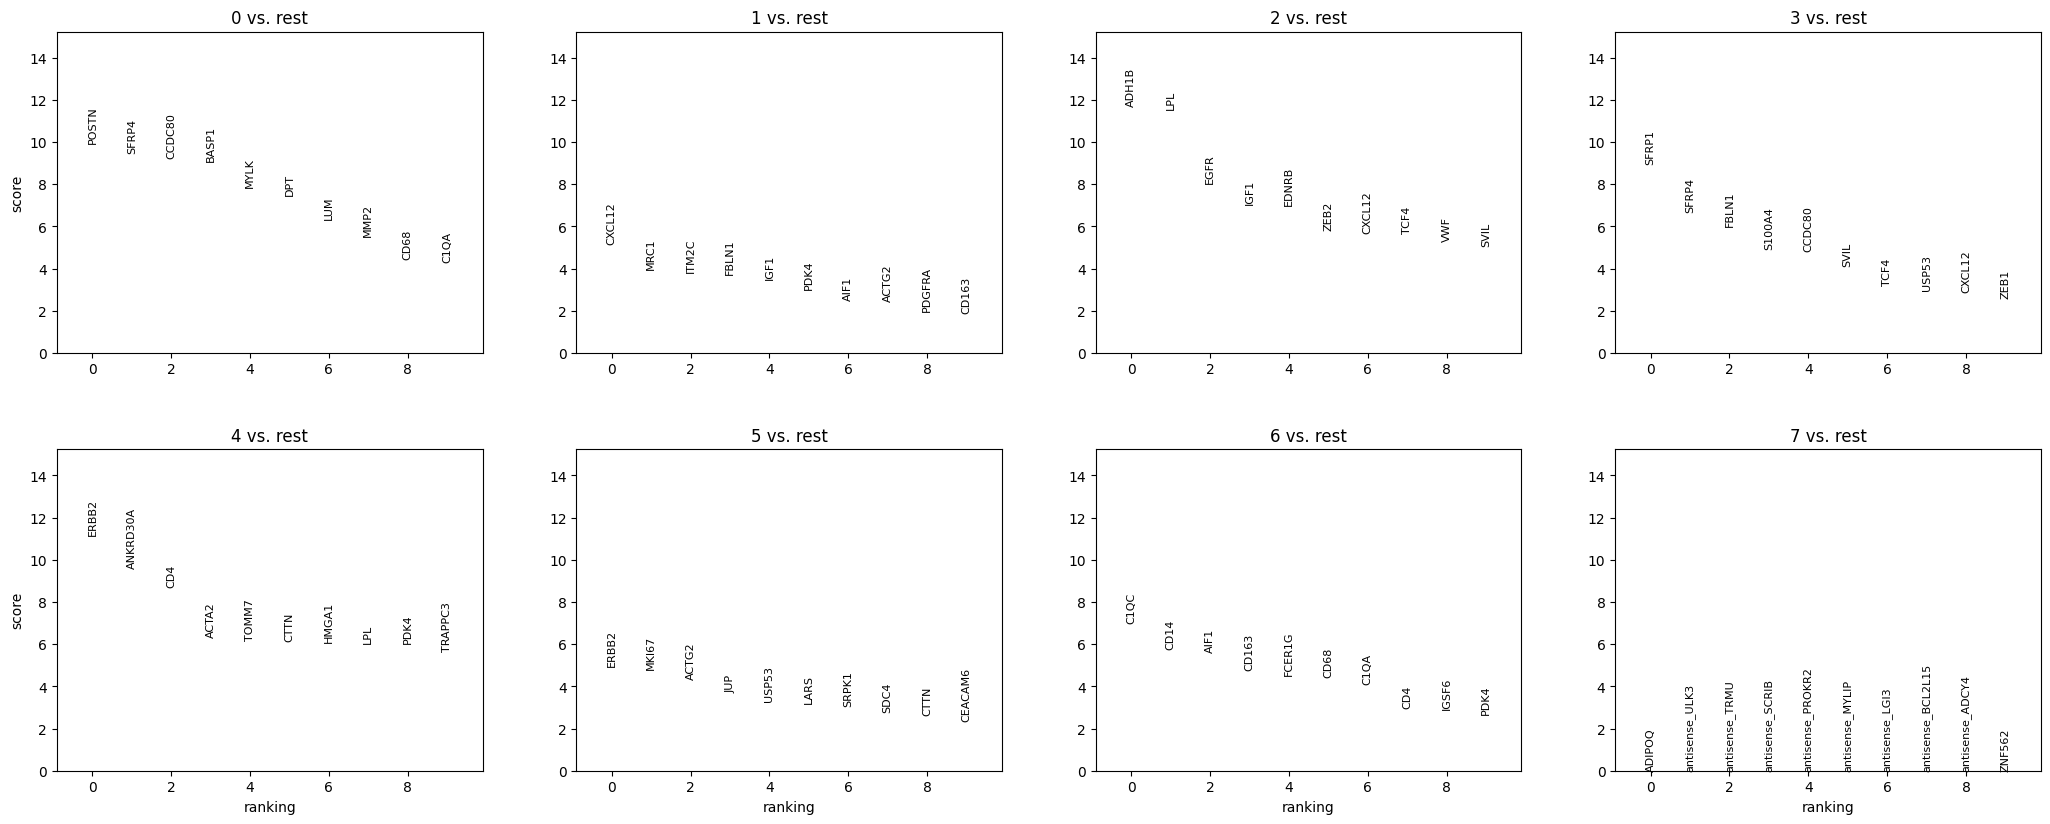

In [189]:
sc.tl.dendrogram(adata, groupby="leiden")
sc.tl.rank_genes_groups(adata, groupby="leiden")
sc.pl.rank_genes_groups(adata, groupby="leiden", n_genes=10)

In [198]:
adata.var.index

Index(['ACTA2', 'ACTG2', 'ADAM9', 'ADGRE5', 'ADH1B', 'AIF1', 'ANKRD28',
       'ANKRD30A', 'AQP1', 'BACE2', 'BASP1', 'C1QA', 'C1QC', 'CAV1', 'CCDC80',
       'CCL5', 'CCPG1', 'CD14', 'CD163', 'CD4', 'CD68', 'CD93', 'CEACAM6',
       'CRISPLD2', 'CTTN', 'CXCL12', 'CXCL16', 'DNTTIP1', 'DPT', 'DUSP5',
       'EDNRB', 'EGFR', 'ERBB2', 'FAM107B', 'FBLN1', 'FCER1G', 'FGL2',
       'GLIPR1', 'HMGA1', 'HOXD8', 'IGF1', 'IGSF6', 'ITM2C', 'JUP', 'KARS',
       'KLRB1', 'LARS', 'LDHB', 'LPL', 'LUM', 'LYZ', 'MAP3K8', 'MKI67', 'MMP2',
       'MRC1', 'MYLK', 'PDGFRA', 'PDGFRB', 'PDK4', 'PECAM1', 'PIM1', 'POSTN',
       'PPARG', 'PTGDS', 'PTN', 'QARS', 'RUNX1', 'S100A4', 'SDC4', 'SERPINA3',
       'SFRP1', 'SFRP4', 'SMS', 'SRPK1', 'SVIL', 'TCF4', 'TOMM7', 'TRAPPC3',
       'TRIB1', 'USP53', 'VWF', 'ZEB1', 'ZEB2'],
      dtype='object')

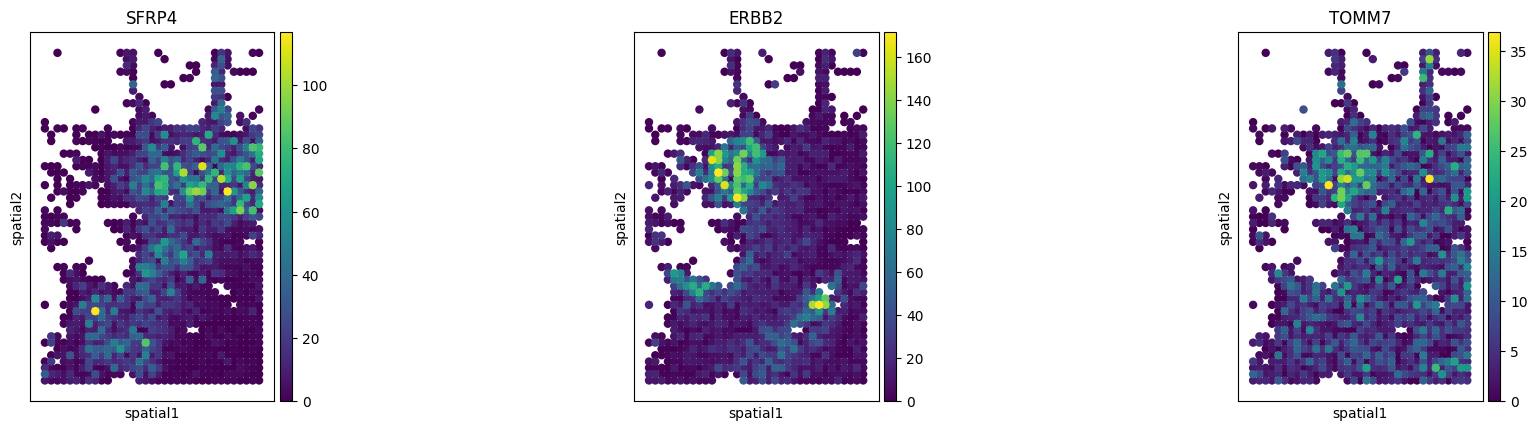

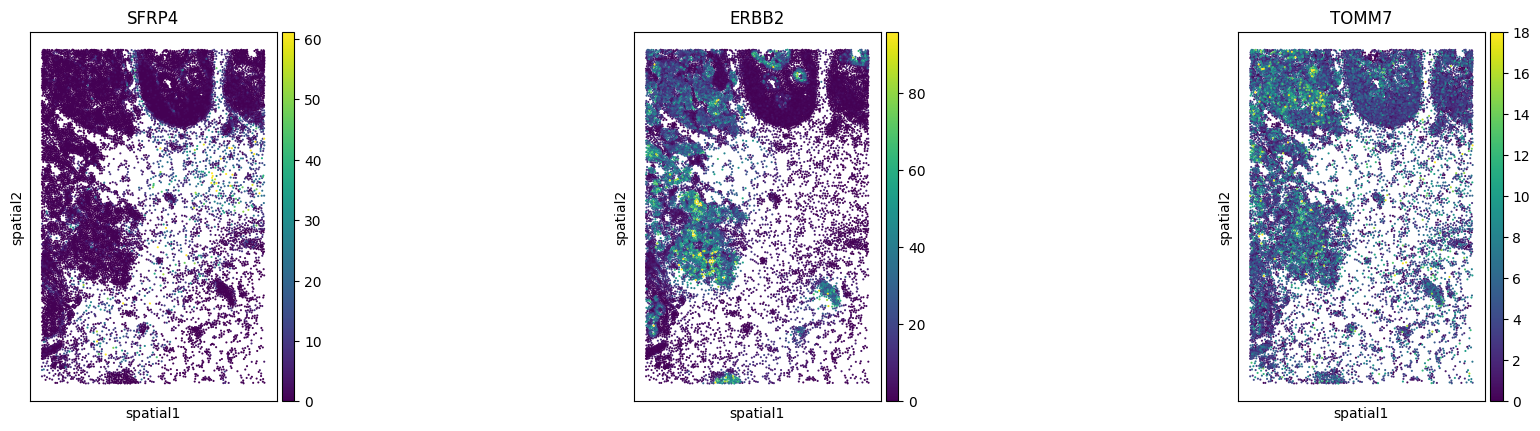

In [212]:
genes = ["SFRP4", "ERBB2", "TOMM7"]
sc.pl.spatial(
    adata, color=genes, spot_size=80, marker="*", outline_width=(0.8, 0.05), outline_color="black", vmax="p99.9"
)
sc.pl.spatial(
    sdata["table"],
    color=genes,
    spot_size=20,
    marker="*",
    outline_width=(0.8, 0.05),
    outline_color="black",
    vmax="p99.9",
)

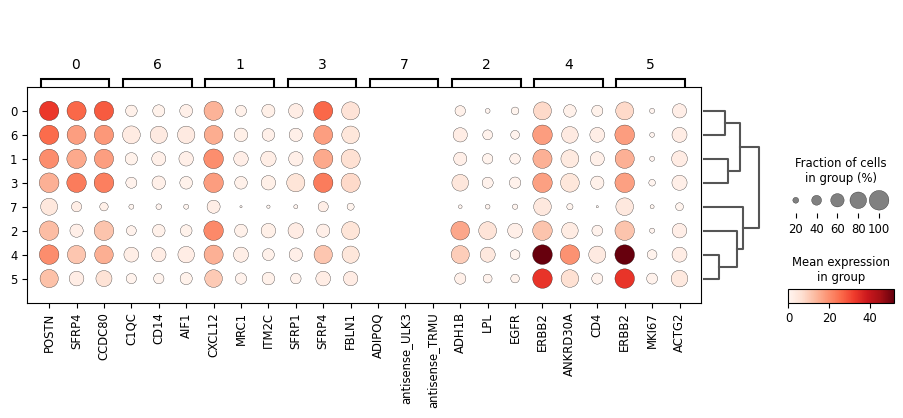

In [199]:
sc.pl.rank_genes_groups_dotplot(adata, groupby="leiden", n_genes=3)

In [213]:
troutpy.tl.latent_factor(sdata, method="NMF", layer="segmentation_free_table", n_components=10)

In [214]:
troutpy.tl.apply_exrna_factors_to_cells(sdata, extracellular_layer="segmentation_free_table", cellular_layer="table")

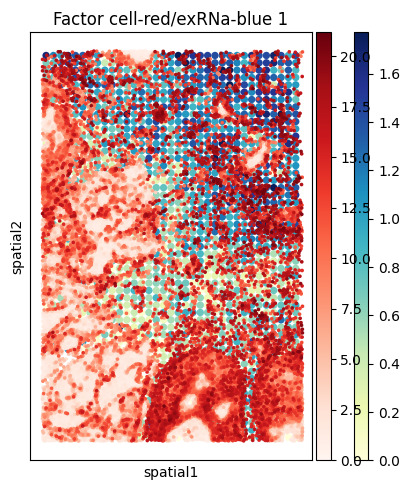

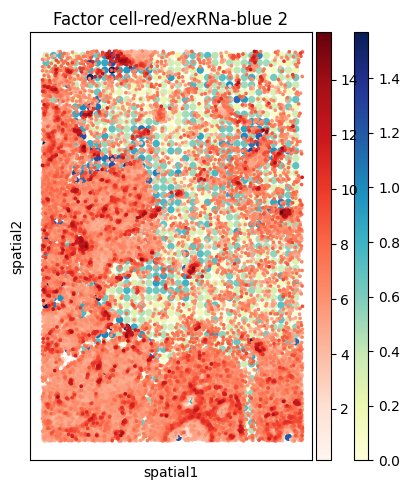

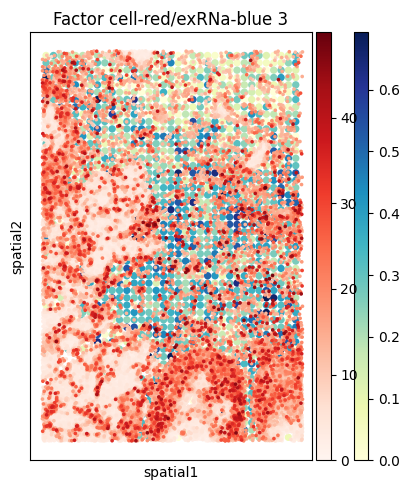

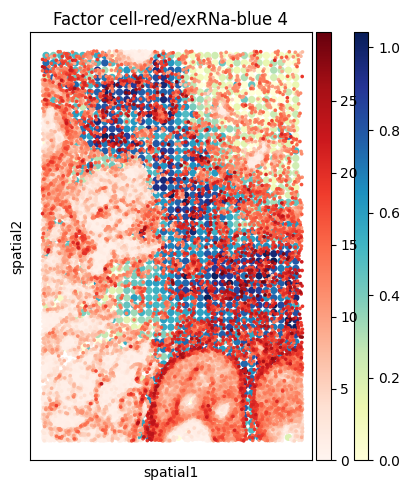

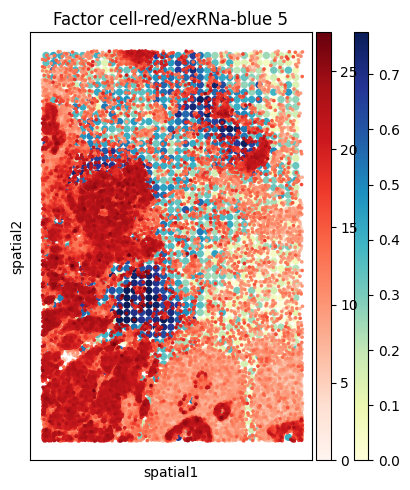

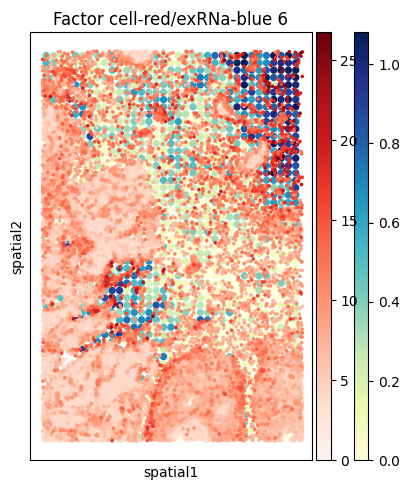

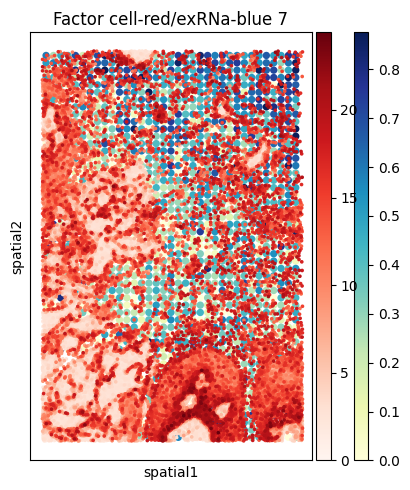

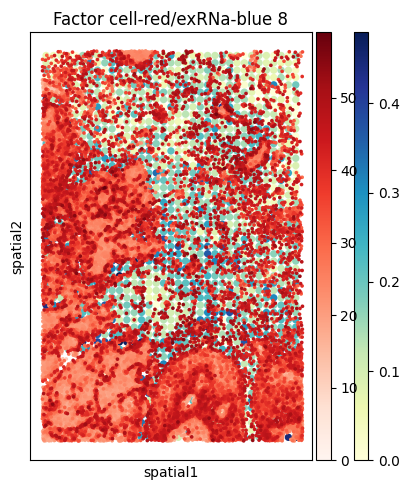

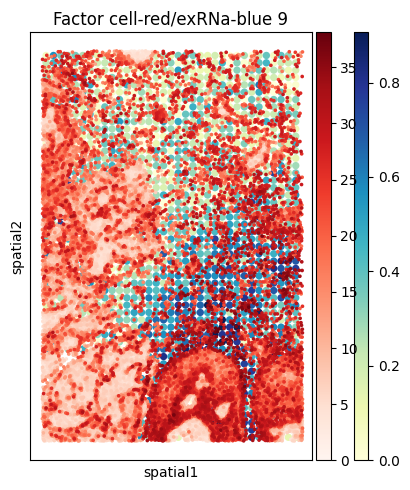

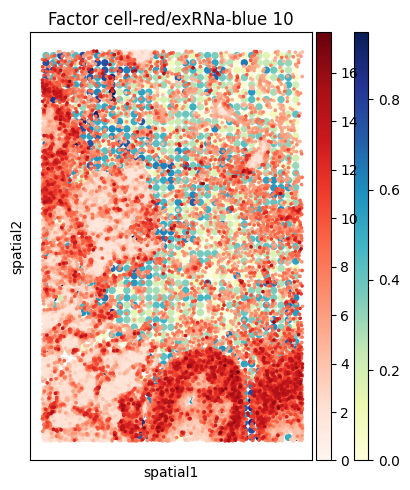

In [222]:
troutpy.pl.paired_nmf_factors(
    sdata, layer="segmentation_free_table", spot_size_exrna=60, spot_size_cells=30, figsize=(5, 5), n_factors=10
)

{'Factor 1': ['CXCL12', 'IGF1'], 'Factor 2': ['ACTG2', 'ACTA2'], 'Factor 3': ['FCER1G', 'PDK4'], 'Factor 4': ['SFRP4', 'CCDC80'], 'Factor 5': ['ANKRD30A', 'ERBB2'], 'Factor 6': ['ADH1B', 'LPL'], 'Factor 7': ['LDHB', 'PDGFRB'], 'Factor 8': ['ERBB2', 'POSTN'], 'Factor 9': ['BASP1', 'POSTN'], 'Factor 10': ['LYZ', 'PTGDS']}


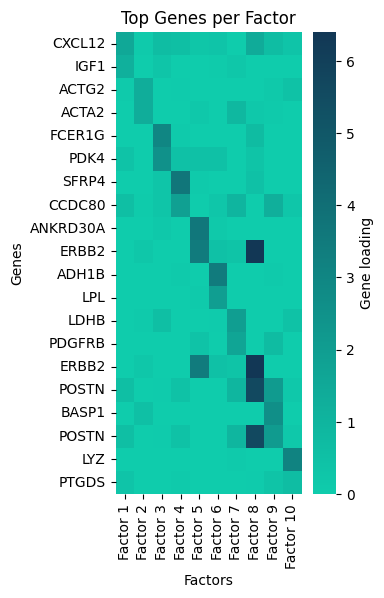

In [220]:
troutpy.pl.rank_factor_genes_loadings_matrixplot(
    sdata, layer="segmentation_free_table", n_genes=2, cmap="troutpy_reversed"
)

In [226]:
sdata

SpatialData object
├── Images
│     ├── 'morphology_focus': DataTree[cyx] (1, 15000, 10000), (1, 7500, 5000), (1, 3749, 2500), (1, 1875, 1250), (1, 938, 625)
│     └── 'morphology_mip': DataTree[cyx] (1, 15000, 10000), (1, 7500, 5000), (1, 3749, 2500), (1, 1875, 1250), (1, 938, 625)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (15000, 10000), (7500, 5000), (3749, 2500), (1875, 1250), (938, 625)
│     └── 'nucleus_labels': DataTree[yx] (15000, 10000), (7500, 5000), (3749, 2500), (1875, 1250), (938, 625)
├── Points
│     ├── 'extracellular_transcripts': DataFrame with shape: (<Delayed>, 9) (3D points)
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 9) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (22205, 1) (2D shapes)
│     ├── 'cell_circles': GeoDataFrame shape: (21877, 2) (2D shapes)
│     ├── 'grid_squares': GeoDataFrame shape: (1855, 1) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (22037, 1) (2D shapes)
└── Tables
      ├──

In [244]:
import numpy as np


def compute_projection_score(sdata):
    """
    Compute a segmentation score for each cell based on the expression of genes
    weighted by their intracellular proportion (1 - extracellular proportion).

    Parameters:
    -----------
    sdata : dict
        A spatialdata object with keys 'table' and 'xrna_metadata'.
        - sdata['table'] is an AnnData object containing expression data in layers['raw']
          and cell metadata in .obs.
        - sdata['xrna_metadata'].var is a DataFrame with gene names as the index and
          an 'extracellular proportion' column.

    Returns:
    --------
    sdata : dict
        The same sdata object with a new column 'segmentation_score' in sdata['table'].obs.
    """

    # Retrieve the AnnData object with cells in .obs and genes in .var
    adata = sdata["table"]

    # Retrieve raw expression data; assume shape (n_cells, n_genes)
    raw_expr = adata.layers["raw"]

    # If raw_expr is a sparse matrix, convert to a dense array
    if hasattr(raw_expr, "toarray"):
        raw_expr = raw_expr.toarray()

    # Get gene names from the AnnData object
    genes = adata.var_names

    # Retrieve gene metadata containing the extracellular proportions
    gene_meta = sdata["xrna_metadata"].var

    # Identify the genes common to both the expression data and the metadata
    common_genes = gene_meta.index.intersection(genes)
    if len(common_genes) == 0:
        raise ValueError("No common genes found between adata and gene metadata.")

    # Subset the expression matrix to only those common genes
    # Here we assume adata.var_names preserves order; get indices corresponding to common genes.
    common_idx = [i for i, gene in enumerate(genes) if gene in common_genes]
    raw_expr = raw_expr[:, common_idx]

    # Reorder gene_meta so that it matches the ordering in the expression data.
    # This assumes that the order of genes in adata.var_names is the desired order.
    ordered_genes = [gene for gene in genes if gene in common_genes]
    gene_weights = gene_meta.loc[ordered_genes, "extracellular_proportion"]

    # Convert extracellular proportion to intracellular weight (1 - extracellular proportion)
    extracellular_weights = gene_weights.values  # numpy array

    # Compute the numerator and denominator for the weighted average per cell.
    # Numerator: dot product of cell expression with intracellular weights.
    # Denominator: total expression (for the common genes) per cell.
    numerator = raw_expr.dot(extracellular_weights)
    denominator = raw_expr.sum(axis=1)

    # Avoid division by zero (if a cell has zero expression for these genes)
    score = np.divide(numerator, denominator, out=np.full_like(numerator, np.nan), where=denominator != 0)

    # Store the score in the AnnData object under obs
    adata.obs["projection_score"] = score


#   return sdata

# Example usage:
# sdata = compute_segmentation_score(sdata)
import numpy as np


def proportion_of_extracellularly_enriched_genes(sdata, threshold=0.5):
    """
    For each cell, compute the proportion of expressed genes that are
    extracellularly enriched, i.e. whose extracellular transcript proportion
    is above a given threshold.

    Parameters:
    -----------
    sdata : dict
        A spatialdata object with keys 'table' and 'xrna_metadata'.
        - sdata['table'] is an AnnData object containing expression data in layers['raw']
          and cell metadata in .obs.
        - sdata['xrna_metadata'].var is a DataFrame with gene names as the index and
          an 'extracellular_proportion' column.

    threshold : float, default=0.5
        The minimum extracellular proportion required for a gene to be considered
        "extracellularly enriched".

    Returns:
    --------
    sdata : dict
        The same sdata object with a new column 'extracellularly_enriched_proportion'
        in sdata['table'].obs, which contains the computed metric for each cell.
    """
    # Retrieve the AnnData object and raw expression data
    adata = sdata["table"]
    raw_expr = adata.layers["raw"]

    # Convert to dense if necessary
    if hasattr(raw_expr, "toarray"):
        raw_expr = raw_expr.toarray()

    # Get gene names from AnnData and the corresponding gene metadata
    genes = adata.var_names
    gene_meta = sdata["xrna_metadata"].var

    # Find common genes between the expression data and metadata
    common_genes = gene_meta.index.intersection(genes)
    if len(common_genes) == 0:
        raise ValueError("No common genes found between adata and gene metadata.")

    # Get indices of common genes in the expression matrix
    common_idx = [i for i, gene in enumerate(genes) if gene in common_genes]
    raw_expr = raw_expr[:, common_idx]

    # Reorder the gene metadata to match the ordering in the expression data
    ordered_genes = [gene for gene in genes if gene in common_genes]
    extracellular_props = gene_meta.loc[ordered_genes, "extracellular_proportion"].values

    # Create a boolean mask for genes that are extracellularly enriched (above threshold)
    enriched_mask = extracellular_props > threshold

    # Determine which genes are expressed in each cell (expression > 0)
    expressed = raw_expr > 0

    # Count the number of expressed genes per cell
    expressed_count = expressed.sum(axis=1)

    # For each cell, count how many of the expressed genes are extracellularly enriched
    enriched_count = (expressed & enriched_mask).sum(axis=1)

    # Compute the proportion (handling potential division by zero)
    proportion = np.divide(
        enriched_count,
        expressed_count,
        out=np.full_like(enriched_count, np.nan, dtype=float),
        where=expressed_count != 0,
    )

    # Store the computed metric in the AnnData object under .obs
    adata.obs["extracellularly_enriched_proportion"] = proportion

In [245]:
compute_projection_score(sdata)
proportion_of_extracellularly_enriched_genes(sdata, threshold=0.1)

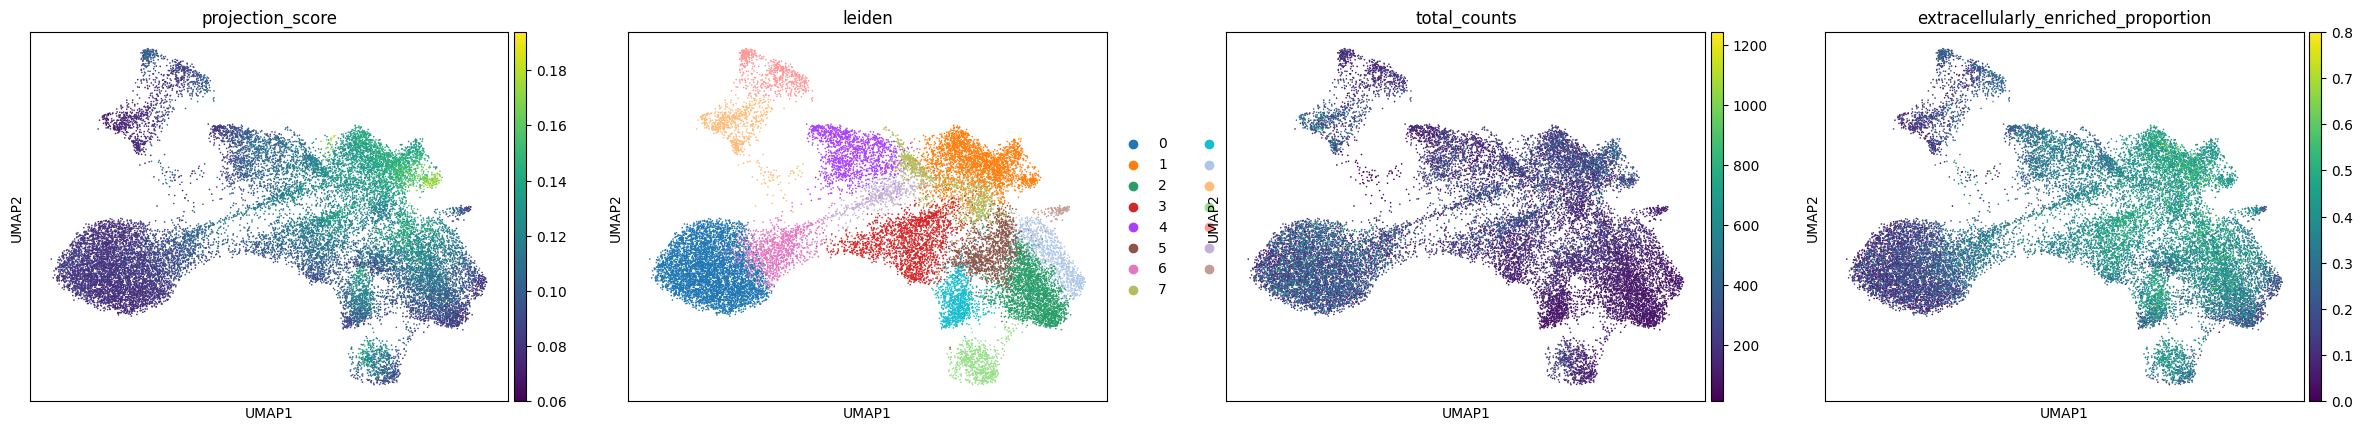

In [246]:
import scanpy as sc

sc.pl.umap(
    sdata["table"],
    color=["projection_score", "leiden", "total_counts", "extracellularly_enriched_proportion"],
    vmax="p99.999",
)

In [ ]:
sc.pl.spatial(sdata["table"], color="projection_score", spot_size=30)

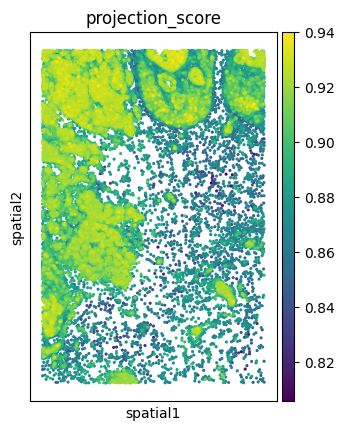

In [237]:
sc.pl.spatial(sdata["table"], color="projection_score", spot_size=30)